# 14 · Re-processing from raw reads: STARsolo, CellBender and RNA velocity

The main analysis starts from the authors' Cell Ranger matrix. Here 8 libraries
(4 control, 4 IPF) were re-processed from FASTQ on the Linux workstation
(`linux_upstream/`) to answer three questions:

1. **Is the published count matrix reproducible?** STARsolo with Cell Ranger-
   compatible options (`_CR` barcode/UMI handling, EmptyDrops_CR cell calling)
   is compared with the GEO matrix: same cells, same counts?
2. **How much ambient RNA is there, and where?** CellBender estimates, for each
   cell, which counts come from the cell-free "soup". In lung the soup is
   dominated by AT2 surfactant and secretory transcripts, which can leak into
   other cell types and fake "intermediate" states - a direct concern for the
   transitional cells studied in Notebook 09.
3. **Can RNA velocity support the trajectory?** 5′ libraries capture few
   intronic reads, so velocity is treated as exploratory and the unspliced
   fraction is reported first.

This notebook runs only when `data/linux_results/results_to_return/` exists.

In [1]:
import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import scipy.sparse as sp
import seaborn as sns
from adjustText import adjust_text
from matplotlib.lines import Line2D
from scipy.stats import pearsonr

from ipfatlas.config import setup
from ipfatlas.plotting import CONDITION_COLORS, LINEAGE_COLORS, figsize, panel_label, save_figure, set_style
from ipfatlas.utils import log, write_table

cfg, P = setup()
set_style(cfg["figures"]["font_size"])
FIG = P.figures / "14_upstream"
TAB = P.tables / "14_upstream"
LR = P.root / "data" / "linux_results" / "results_to_return"
assert LR.exists(), f"Linux results not found in {LR} (see linux_upstream/README.md)"

samples = pd.read_csv(LR / "samples.tsv", sep="\t")
libs = sorted(p.stem for p in (LR / "h5ad").glob("*.h5ad"))
dx = samples.drop_duplicates("library_id").set_index("library_id")["diagnosis"]
print(f"{len(libs)} re-processed libraries:", ", ".join(f"{l} ({dx.get(l, '?')})" for l in libs))
print((LR / "RUN_INFO.txt").read_text())

8 re-processed libraries: F00409 (Control), F00431 (IPF), F01157 (Control), F01174 (Control), F01214 (IPF), F01390 (IPF), F01394 (Control), ILD63 (IPF)
host: AhmedB
date: 2026-10-30T12:44:38+01:00
threads: 16
mem_gb: 62
test_mode: 0



## 1. STARsolo mapping and cell-calling metrics

In [2]:
summ = pd.read_csv(LR / "starsolo" / "starsolo_summary.tsv", sep="\t", index_col=0)
keep_cols = ["Number of Reads", "Reads With Valid Barcodes", "Sequencing Saturation", "Q30 Bases in RNA read",
             "Reads Mapped to Genome: Unique", "Reads Mapped to Gene: Unique Gene", "Estimated Number of Cells",
             "Fraction of Unique Reads in Cells", "Median UMI per Cell", "Median Gene per Cell"]
summ = summ[[c for c in keep_cols if c in summ.columns]]
summ.insert(0, "diagnosis", summ.index.map(dx))
write_table(summ, TAB / "starsolo_summary")
summ

,diagnosis,Number of Reads,Reads With Valid Barcodes,Sequencing Saturation,Q30 Bases in RNA read,Reads Mapped to Genome: Unique,Reads Mapped to Gene: Unique Gene,Estimated Number of Cells,Fraction of Unique Reads in Cells,Median UMI per Cell,Median Gene per Cell
library_id,,,,,,,,,,,
F00409,Control,64358680,0.881532,0.773591,0.848768,0.788481,0.495528,1367,0.487675,1711,1047
F00431,IPF,68435661,0.913444,0.506139,0.806368,0.841050,0.648397,2820,0.790297,5506,1872
F01157,Control,161706693,0.917499,0.689969,0.871105,0.818703,0.635656,3314,0.818392,6640,2134
F01174,Control,93607106,0.911635,0.526076,0.889179,0.844916,0.656281,3233,0.778071,6695,2072
F01214,IPF,38836489,0.913364,0.283237,0.887052,0.843460,0.653405,2901,0.608471,2628,1093
F01390,IPF,58112773,0.950461,0.451085,0.833370,0.746579,0.605376,3558,0.515944,1779,797
F01394,Control,55765054,0.944277,0.245021,0.848666,0.795617,0.657005,9295,0.610274,1348,639
ILD63,IPF,305878532,0.904430,0.805608,0.898721,0.840074,0.606175,7397,0.616300,1229,527


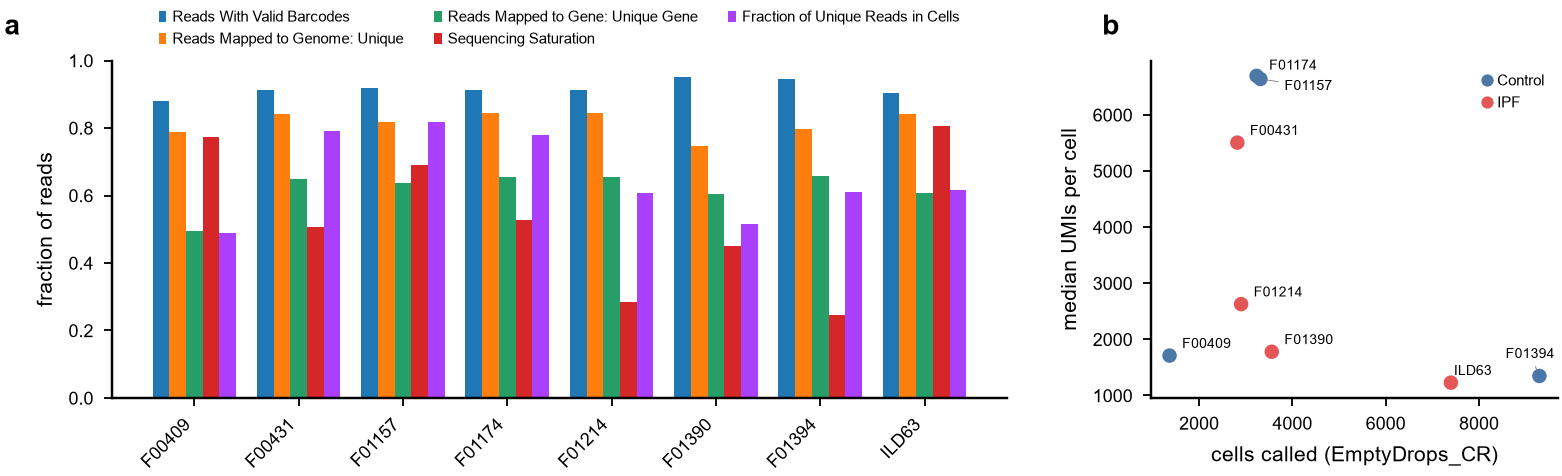

In [3]:
frac = ["Reads With Valid Barcodes", "Reads Mapped to Genome: Unique", "Reads Mapped to Gene: Unique Gene",
        "Sequencing Saturation", "Fraction of Unique Reads in Cells"]
frac = [c for c in frac if c in summ.columns]
fig, axes = plt.subplots(1, 2, figsize=figsize(183, 60), gridspec_kw={"width_ratios": [2.2, 1]})
x = np.arange(len(summ))
w = 0.8 / len(frac)
for i, c in enumerate(frac):
    axes[0].bar(x + i * w - 0.4 + w / 2, summ[c].astype(float), width=w, label=c)
axes[0].set_xticks(x, summ.index, rotation=45, ha="right")
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("fraction of reads")
axes[0].legend(fontsize=5, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False)
axes[1].scatter(summ["Estimated Number of Cells"], summ["Median UMI per Cell"], s=14,
                c=[CONDITION_COLORS.get(d, "grey") for d in summ["diagnosis"]])
texts = [axes[1].text(r["Estimated Number of Cells"], r["Median UMI per Cell"], lib, fontsize=4.5)
         for lib, r in summ.iterrows()]
adjust_text(texts, x=summ["Estimated Number of Cells"].to_numpy(float), y=summ["Median UMI per Cell"].to_numpy(float),
            ax=axes[1], expand=(1.3, 1.8), arrowprops={"arrowstyle": "-", "lw": 0.3, "color": "grey"})
dx_handles = [Line2D([], [], ls="", marker="o", ms=3, color=CONDITION_COLORS[d], label=d) for d in ("Control", "IPF")]
axes[1].legend(handles=dx_handles, fontsize=5, frameon=False)
axes[1].set_xlabel("cells called (EmptyDrops_CR)")
axes[1].set_ylabel("median UMIs per cell")
for a, l in zip(axes, "ab"):
    panel_label(a, l)
fig.tight_layout()
save_figure(fig, "S14_starsolo_metrics", FIG)
plt.show()

**Result.** All eight libraries mapped well: 88–95 % of reads had a valid barcode,
75–84 % mapped uniquely to the genome and 50–66 % uniquely to a gene. EmptyDrops_CR
called 1,367–9,295 cells per library, 33,885 in total. Sequencing saturation ranges
from 0.25 (F01394) to 0.81 (ILD63) and follows sequencing depth (39–306 M reads).
F00409 has the lowest fraction of reads in cells (0.49) and the fewest cells, but no
library is unusable.

## 2. STARsolo vs the published Cell Ranger matrix
For each library: overlap of called barcodes, per-cell UMI agreement on shared
barcodes, and per-gene agreement of the library pseudobulk (log CPM).

In [4]:
geo = sc.read_h5ad(P.interim / "discovery_raw.h5ad")
ann = sc.read_h5ad(P.processed / "discovery_annotated.h5ad", backed="r")
ann_obs = ann.obs[["cell_type", "compartment", "diagnosis"]].copy()
umap = pd.DataFrame(ann.obsm["X_umap"], index=ann.obs_names, columns=["u1", "u2"])
ann.file.close()

rows, gene_cor, solo = [], {}, {}
for lib in libs:
    a = sc.read_h5ad(LR / "h5ad" / f"{lib}.h5ad")
    solo[lib] = a
    g = geo[geo.obs["library_id"] == lib]
    shared_bc = a.obs_names.intersection(g.obs_names)
    shared_genes = a.var_names.intersection(g.var_names)
    u_s = np.asarray(a[shared_bc, shared_genes].X.sum(axis=1)).ravel()
    u_g = np.asarray(g[shared_bc, shared_genes].X.sum(axis=1)).ravel()
    pb_s = np.asarray(a[:, shared_genes].X.sum(axis=0)).ravel()
    pb_g = np.asarray(g[:, shared_genes].X.sum(axis=0)).ravel()
    ok = (pb_s + pb_g) > 0
    l_s, l_g = np.log2(pb_s / pb_s.sum() * 1e6 + 1), np.log2(pb_g / pb_g.sum() * 1e6 + 1)
    gene_cor[lib] = pd.DataFrame({"log2cpm_starsolo": l_s, "log2cpm_cellranger": l_g}, index=shared_genes)[ok]
    in_ann = shared_bc.isin(ann_obs.index)
    rows.append({"library_id": lib, "diagnosis": dx.get(lib), "cells_starsolo": a.n_obs, "cells_cellranger": g.n_obs,
                 "shared_barcodes": len(shared_bc), "jaccard": len(shared_bc) / len(a.obs_names.union(g.obs_names)),
                 "frac_annotated_cells_recovered": ann_obs.index[ann_obs.index.str.startswith(lib + "_")].isin(a.obs_names).mean(),
                 "pearson_log_umi_per_cell": pearsonr(np.log1p(u_s), np.log1p(u_g))[0],
                 "median_umi_ratio_starsolo_to_cr": float(np.median(u_s / np.maximum(u_g, 1))),
                 "pearson_log2cpm_genes": pearsonr(l_s[ok], l_g[ok])[0],
                 "annotated_in_shared": int(in_ann.sum())})
conc = pd.DataFrame(rows).set_index("library_id")
write_table(conc.round(4), TAB / "starsolo_vs_cellranger")
conc.round(3)

,diagnosis,cells_starsolo,cells_cellranger,shared_barcodes,jaccard,frac_annotated_cells_recovered,pearson_log_umi_per_cell,median_umi_ratio_starsolo_to_cr,pearson_log2cpm_genes,annotated_in_shared
library_id,,,,,,,,,,
F00409,Control,1367,1379,1359,0.980,0.995,0.999,0.972,0.988,981
F00431,IPF,2820,2831,2806,0.986,0.999,1.000,0.980,0.992,2162
F01157,Control,3314,3260,3179,0.936,0.996,1.000,0.983,0.995,2249
F01174,Control,3233,3253,3214,0.982,0.999,1.000,0.975,0.993,2651
F01214,IPF,2901,3018,2894,0.957,1.000,1.000,0.963,0.990,1780
F01390,IPF,3558,3641,3557,0.977,1.000,1.000,0.978,0.992,2041
F01394,Control,9295,9619,9285,0.964,1.000,1.000,0.969,0.992,5136
ILD63,IPF,7397,7538,7362,0.972,1.000,1.000,0.986,0.994,2866


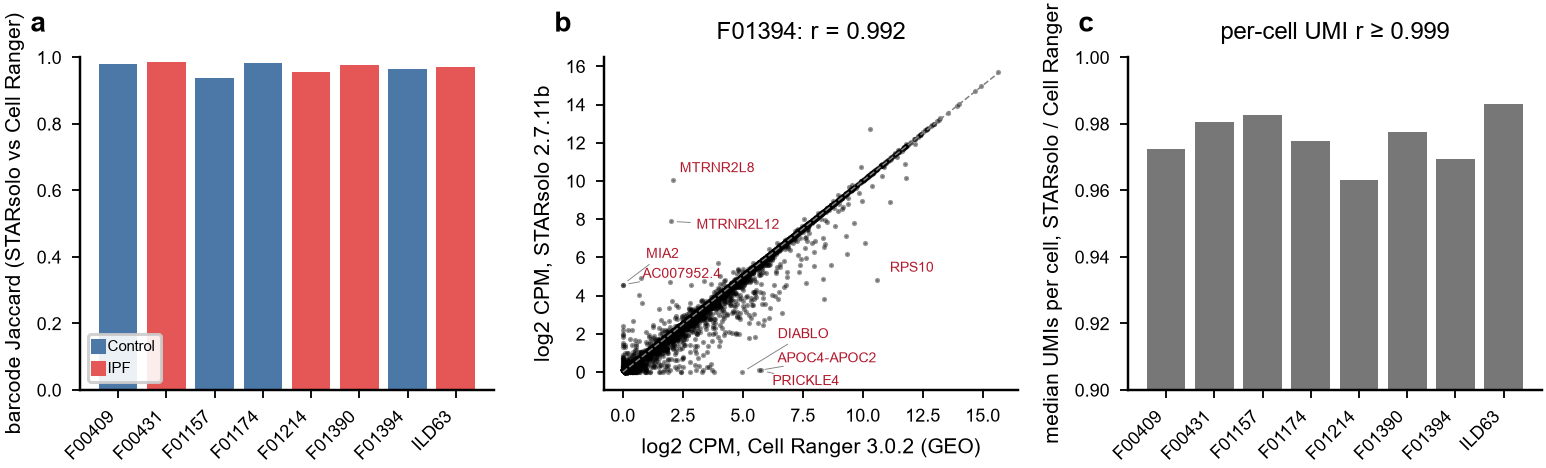

In [5]:
lib0 = conc["cells_starsolo"].idxmax()
gc = gene_cor[lib0]
diff = (gc["log2cpm_starsolo"] - gc["log2cpm_cellranger"]).sort_values()
write_table(diff.rename("log2cpm_difference").to_frame().round(3), TAB / f"gene_differences_{lib0}")

fig, axes = plt.subplots(1, 3, figsize=figsize(183, 58))
axes[0].bar(range(len(conc)), conc["jaccard"], color=[CONDITION_COLORS.get(d, "grey") for d in conc["diagnosis"]])
axes[0].set_xticks(range(len(conc)), conc.index, rotation=45, ha="right")
axes[0].set_ylabel("barcode Jaccard (STARsolo vs Cell Ranger)")
axes[0].set_ylim(0, 1)
axes[0].legend(handles=[Line2D([], [], ls="", marker="s", ms=4, color=CONDITION_COLORS[d], label=d)
                        for d in ("Control", "IPF")], fontsize=5, loc="lower left", frameon=True, framealpha=0.9)
axes[1].scatter(gc["log2cpm_cellranger"], gc["log2cpm_starsolo"], s=0.5, color="black", alpha=0.4, rasterized=True)
lab = list(diff.index[:4]) + list(diff.index[-4:])
texts = [axes[1].text(gc.loc[g_, "log2cpm_cellranger"], gc.loc[g_, "log2cpm_starsolo"], g_, fontsize=4.5,
                      color="#B2182B") for g_ in lab]
adjust_text(texts, x=gc.loc[lab, "log2cpm_cellranger"].to_numpy(), y=gc.loc[lab, "log2cpm_starsolo"].to_numpy(),
            ax=axes[1], expand=(1.3, 1.8), arrowprops={"arrowstyle": "-", "lw": 0.3, "color": "grey"})
axes[1].plot([0, gc.values.max()], [0, gc.values.max()], lw=0.5, ls="--", color="grey")
axes[1].set_xlabel("log2 CPM, Cell Ranger 3.0.2 (GEO)")
axes[1].set_ylabel("log2 CPM, STARsolo 2.7.11b")
axes[1].set_title(f"{lib0}: r = {conc.loc[lib0, 'pearson_log2cpm_genes']:.3f}")
# per-cell UMI correlations are all >= 0.999, so show the size of the difference instead
axes[2].bar(range(len(conc)), conc["median_umi_ratio_starsolo_to_cr"], color="#777777")
axes[2].set_xticks(range(len(conc)), conc.index, rotation=45, ha="right")
axes[2].set_ylim(0.9, 1.0)
axes[2].set_ylabel("median UMIs per cell, STARsolo / Cell Ranger")
axes[2].set_title(f"per-cell UMI r ≥ {conc['pearson_log_umi_per_cell'].min():.3f}")
for a, l in zip(axes, "abc"):
    panel_label(a, l)
fig.tight_layout()
save_figure(fig, "S14_starsolo_vs_cellranger", FIG)
plt.show()

**Result.** STARsolo reproduces the published matrix. The called barcodes overlap
with a Jaccard index of 0.94–0.99, and 99.5–100 % of the cells annotated in the atlas
are recovered. On shared barcodes, per-cell UMI totals correlate at r ≥ 0.999 (log
scale), STARsolo counting 1–4 % fewer UMIs per cell (median ratio 0.963–0.986), and
the library pseudobulks agree at r = 0.988–0.995 over genes. The genes that differ
most (*MTRNR2L8* and *MTRNR2L12* higher in STARsolo; *RPS10*, *PRICKLE4*,
*APOC4-APOC2* and *DIABLO* lower) are nuclear paralogs of mitochondrial genes,
readthrough transcripts and genes that overlap others, where the two tools likely
handle multimapping reads and overlapping annotations differently. The analysis in
Notebooks 01–13, which starts from the GEO matrix, does not depend on the aligner.

## 3. Ambient RNA (CellBender)
For every annotated cell: fraction of its (STARsolo Gene) counts removed by
CellBender. The *soup profile* is the sum of removed counts per gene.

In [6]:
def read_cellbender(path):
    """CellBender 0.3 filtered output (10x HDF5 v3 layout) -> cells x genes CSR, barcodes, Ensembl IDs.

    Genes are matched by Ensembl ID: GRCh38-3.0.0 has duplicated symbols (TBCE, RGS5, ...).
    """
    with h5py.File(path, "r") as f:
        m = f["matrix"]
        x = sp.csc_matrix((m["data"][:], m["indices"][:], m["indptr"][:]), shape=tuple(m["shape"][:])).T.tocsr()
        bc = [b.decode() for b in m["barcodes"][:]]
        gene_ids = pd.Index([g.decode() for g in m["features"]["id"][:]])
    return x, bc, gene_ids


amb_cells, soup = [], {}
for lib in libs:
    f = LR / "cellbender" / lib / "cellbender_filtered.h5"
    if not f.exists():
        log.warning(f"{lib}: no CellBender output")
        continue
    x_cb, bc_cb, genes_cb = read_cellbender(f)
    a = solo[lib]
    bc_cb = [f"{lib}_{b.split('-')[0]}" for b in bc_cb]
    cb = pd.Index(bc_cb)
    shared = a.obs_names.intersection(cb).intersection(ann_obs.index)
    gi = genes_cb.get_indexer(a.var["gene_ids"])
    ok = gi >= 0
    raw = a[shared].X[:, np.where(ok)[0]]
    corr = x_cb[cb.get_indexer(shared)][:, gi[ok]]
    removed = (raw - corr)
    removed.data = np.clip(removed.data, 0, None)
    tot_raw = np.asarray(raw.sum(axis=1)).ravel()
    tot_rem = np.asarray(removed.sum(axis=1)).ravel()
    amb_cells.append(pd.DataFrame({"library_id": lib, "ambient_fraction": tot_rem / np.maximum(tot_raw, 1)}, index=shared))
    soup[lib] = pd.Series(np.asarray(removed.sum(axis=0)).ravel(), index=a.var_names[ok])
amb = pd.concat(amb_cells).join(ann_obs)
soup = pd.DataFrame(soup).fillna(0)
soup_frac = soup.div(soup.sum(axis=0), axis=1)
write_table(amb.groupby("cell_type", observed=True)["ambient_fraction"].describe().round(4), TAB / "ambient_fraction_per_celltype")
write_table(soup_frac.mean(axis=1).sort_values(ascending=False).head(50).rename("mean_fraction_of_soup").to_frame().round(5),
            TAB / "soup_profile_top50")
soup_frac.mean(axis=1).sort_values(ascending=False).head(15).round(4)

FTL        0.0480
MT-CO2     0.0433
SFTPC      0.0406
MT-CO1     0.0405
FTH1       0.0401
MT-CO3     0.0263
MALAT1     0.0231
SCGB3A1    0.0214
EEF1A1     0.0202
RPL41      0.0193
RPLP1      0.0182
MT-CYB     0.0178
SCGB1A1    0.0171
MT-ND3     0.0169
TPT1       0.0138
dtype: float64

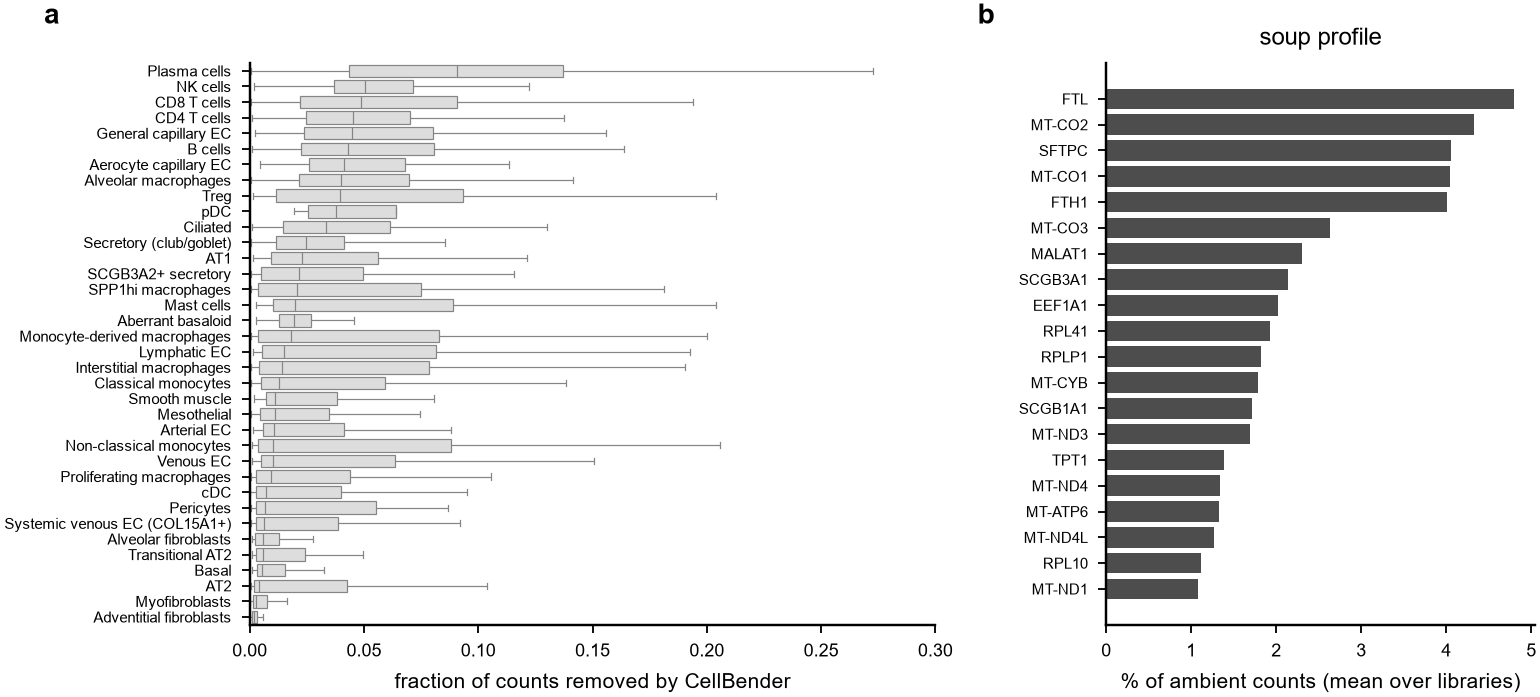

In [7]:
order = amb.groupby("cell_type", observed=True)["ambient_fraction"].median().sort_values(ascending=False).index
top_soup = soup_frac.mean(axis=1).sort_values(ascending=False).head(20)
fig, axes = plt.subplots(1, 2, figsize=figsize(183, 85), gridspec_kw={"width_ratios": [1.6, 1]})
sns.boxplot(amb, y="cell_type", x="ambient_fraction", order=order, ax=axes[0], fliersize=0, linewidth=0.4,
            color="#DDDDDD")
axes[0].set_xlabel("fraction of counts removed by CellBender")
axes[0].set_xlim(0, 0.3)  # hidden outliers would otherwise stretch the axis to ~0.9
axes[0].set_ylabel("")
axes[0].tick_params(axis="y", labelsize=5)
axes[1].barh(range(len(top_soup))[::-1], top_soup.values * 100, color="#4D4D4D")
axes[1].set_yticks(range(len(top_soup))[::-1], top_soup.index, fontsize=5)
axes[1].set_xlabel("% of ambient counts (mean over libraries)")
axes[1].set_title("soup profile")
for a, l in zip(axes, "ab"):
    panel_label(a, l, x=-0.3)
fig.tight_layout()
save_figure(fig, "S14_cellbender_ambient", FIG)
plt.show()

**Result.** Ambient RNA is modest in these libraries: in every cell type except
plasma cells (median 9 %), the median cell lost at most 5 % of its counts. The
soup is dominated by ferritin (*FTL*, *FTH1*), mitochondrial transcripts, *SFTPC* and
*SCGB3A1*, i.e. transcripts of the abundant macrophages, AT2 and secretory cells.
Contamination is highest in lymphocytes, plasma cells and capillary EC (medians
4–9 %) and lowest in fibroblasts, AT2, basal and transitional AT2 cells (medians
0.2–0.6 %); aberrant basaloid cells are in between (1.9 %).

### Does ambient RNA explain the transitional / aberrant basaloid profiles?
If the KRT17⁺ aberrant basaloid or KRT8ʰⁱ transitional signatures were
soup-derived, CellBender would remove a large share of these marker counts in
those cells. We compare marker counts before and after correction.

In [8]:
check = {"Aberrant basaloid": ["KRT17", "LAMB3", "MMP7", "COL1A1", "SFTPC"],
         "Transitional AT2": ["KRT8", "CLDN4", "SFN", "SFTPC"],
         "Alveolar macrophages": ["SFTPC", "SCGB1A1", "MARCO"]}
rows = []
for lib in libs:
    f = LR / "cellbender" / lib / "cellbender_filtered.h5"
    if not f.exists():
        continue
    x_cb, bc_cb, genes_cb = read_cellbender(f)
    cb = pd.Index([f"{lib}_{b.split('-')[0]}" for b in bc_cb])
    a = solo[lib]
    for ct, genes in check.items():
        cells = amb.index[(amb["library_id"] == lib) & (amb["cell_type"] == ct)]
        if len(cells) < 5:
            continue
        for gname in genes:
            if gname not in a.var_names or a.var.loc[gname, "gene_ids"] not in genes_cb:
                continue
            before = np.asarray(a[cells, gname].X.sum()).item()
            after = x_cb[cb.get_indexer(cells)][:, genes_cb.get_loc(a.var.loc[gname, "gene_ids"])].sum()
            rows.append({"library_id": lib, "cell_type": ct, "gene": gname, "n_cells": len(cells),
                         "counts_before": before, "counts_after": after})
mk = pd.DataFrame(rows)
mk_sum = mk.groupby(["cell_type", "gene"])[["counts_before", "counts_after"]].sum()
mk_sum["fraction_retained"] = mk_sum["counts_after"] / mk_sum["counts_before"].replace(0, np.nan)
write_table(mk_sum.round(3), TAB / "marker_counts_before_after_cellbender")
mk_sum.round(3)

counts_before  counts_after  fraction_retained
cell_type            gene                                                   
Aberrant basaloid    COL1A1           669.0           667              0.997
                     KRT17           2698.0          2698              1.000
                     LAMB3            361.0           361              1.000
                     MMP7            1495.0          1495              1.000
                     SFTPC             46.0             7              0.152
Alveolar macrophages MARCO          16643.0         16635              1.000
                     SCGB1A1         1357.0           146              0.108
                     SFTPC           2525.0           206              0.082
Transitional AT2     CLDN4            157.0           157              1.000
                     KRT8             244.0           244              1.000
                     SFN              108.0           108              1.000
                     SFTPC           4505.0          4438              0.985

**Result.** CellBender kept essentially all marker counts of the two disputed
states: *KRT17*, *MMP7* and *LAMB3* in aberrant basaloid cells (100 %; *COL1A1*
99.7 %) and *KRT8*, *CLDN4* and *SFN* in transitional AT2 cells (100 %). These
signatures are made by the cells, not picked up from the soup. The controls behave
as expected: *SFTPC* and *SCGB1A1* counts in alveolar macrophages are almost all
removed (8 % and 11 % retained) while *MARCO* is kept (100 %). *SFTPC* in aberrant
basaloid cells is also mostly ambient (15 % retained), whereas transitional AT2
cells keep 98.5 % of theirs: they still express the AT2 programme, consistent with
their position between AT2 and aberrant basaloid cells in Notebook 09.

## 4. RNA velocity (exploratory)

In [9]:
import scvelo as scv  # noqa: E402

set_style(cfg["figures"]["font_size"])  # importing scvelo changes the matplotlib defaults
frames = []
for lib in libs:
    a = solo[lib]
    if "spliced" not in a.layers:
        continue
    frames.append(a[a.obs_names.isin(ann_obs.index)].copy())
vel = sc.concat(frames, merge="same")
vel.obs = vel.obs.join(ann_obs)
uf = vel.obs.groupby("cell_type", observed=True)["frac_unspliced"].agg(["median", "size"])
write_table(uf.round(4), TAB / "unspliced_fraction_per_celltype")
print(f"median unspliced fraction: {vel.obs['frac_unspliced'].median():.3f}")
uf.sort_values("median", ascending=False).round(3).head(12)

median unspliced fraction: 0.089


,median,size
cell_type,,
Ciliated,0.192,718
CD4 T cells,0.185,564
Aberrant basaloid,0.166,105
AT1,0.157,216
Aerocyte capillary EC,0.149,125
Mast cells,0.144,77
General capillary EC,0.141,249
Classical monocytes,0.137,1318
B cells,0.133,128


Filtered out 25877 genes that are detected 10 counts (shared).
Normalized count data: X, spliced, unspliced.


computing moments based on connectivities


    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)
computing velocities


J:\Programsv1\Anaconda_envs\scrna-ipf\Lib\site-packages\scvelo\tools\optimization.py:184: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  gamma[i] = np.linalg.pinv(A.T.dot(A)).dot(A.T.dot(y[:, i]))


    finished (0:00:00) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 8/20 cores)


  0%|          | 0/4135 [00:00<?, ?cells/s]

    finished (0:00:05) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)


--> added 'velocity_length' (adata.obs)
--> added 'velocity_confidence' (adata.obs)
--> added 'velocity_confidence_transition' (adata.obs)
computing velocity embedding


    finished (0:00:00) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


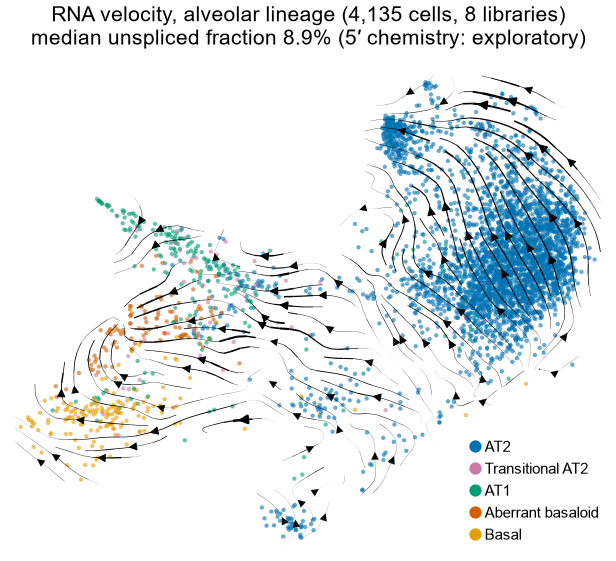

,velocity_confidence,velocity_length
cell_type,,
AT1,0.932,8.370
AT2,0.900,3.250
Transitional AT2,0.803,4.495
Aberrant basaloid,0.920,5.470
Basal,0.836,4.365


In [10]:
lineage = cfg["trajectory"]["lineage"]
v = vel[vel.obs["cell_type"].isin(lineage)].copy()
v.obsm["X_umap"] = umap.loc[v.obs_names].to_numpy()
# scVelo 0.3 no longer selects genes or log-transforms in filter_and_normalize: same steps, explicitly
scv.pp.filter_and_normalize(v, min_shared_counts=10)
sc.pp.log1p(v)
sc.pp.highly_variable_genes(v, n_top_genes=2000)
v = v[:, v.var["highly_variable"]].copy()
sc.pp.pca(v, n_comps=30)
sc.pp.neighbors(v, n_pcs=30, n_neighbors=30)
scv.pp.moments(v, n_pcs=None, n_neighbors=None)
scv.tl.velocity(v, mode="stochastic")
scv.tl.velocity_graph(v, n_jobs=8)
scv.tl.velocity_confidence(v)
conf = v.obs.groupby("cell_type", observed=True)[["velocity_confidence", "velocity_length"]].median()
write_table(conf.round(3), TAB / "velocity_confidence_per_celltype")

v.obs["cell_type"] = pd.Categorical(v.obs["cell_type"].astype(str), categories=lineage)
v.uns["cell_type_colors"] = [LINEAGE_COLORS[c] for c in lineage]  # the colours of Figure 4
fig, ax = plt.subplots(figsize=figsize(90, 75))
scv.pl.velocity_embedding_stream(v, basis="umap", color="cell_type", ax=ax, show=False, legend_loc="none",
                                 size=8, alpha=0.6, linewidth=0.5, arrow_size=0.6, title="")
lo, hi = np.quantile(v.obsm["X_umap"], [0.001, 0.999], axis=0)  # a few stray cells would shrink the plot
pad = 0.05 * (hi - lo)
ax.set_xlim(lo[0] - pad[0], hi[0] + pad[0])
ax.set_ylim(lo[1] - pad[1], hi[1] + pad[1])
ax.legend(handles=[Line2D([], [], ls="", marker="o", ms=3, color=LINEAGE_COLORS[c], label=c) for c in lineage],
          fontsize=5, loc="lower right", frameon=False)
ax.set_title(f"RNA velocity, alveolar lineage ({v.n_obs:,} cells, 8 libraries)\n"
             f"median unspliced fraction {vel.obs['frac_unspliced'].median():.1%} (5′ chemistry: exploratory)",
             fontsize=7)
save_figure(fig, "S14_velocity_stream_lineage", FIG)
plt.show()
conf.round(3)

**Result.** The unspliced fraction is low (median 8.9 % of counts per cell, 4–19 %
across cell types), as expected for 5′ libraries, which capture few intronic reads.
In the 4,135 alveolar lineage cells, the velocity stream leaves the AT2 cluster
towards AT1, aberrant basaloid and basal cells, the direction of the pseudotime and
CellRank fates of Notebook 09, which did not use velocity. Velocity confidence (the
local coherence of the vectors) is high in all five cell types (medians 0.80–0.93),
lowest in transitional AT2 cells. With only 46 transitional AT2 cells, few unspliced
reads and a stochastic model that assumes constant kinetics, this is qualitative
support for the trajectory, not independent evidence.

## Summary

| question | result |
|---|---|
| mapping and cell calling | 88–95 % valid barcodes, 75–84 % unique to the genome; 33,885 cells in 8 libraries |
| is the GEO matrix reproducible? | yes: barcode Jaccard 0.94–0.99; ≥ 99.5 % of annotated cells recovered; per-cell UMI r ≥ 0.999; genes r = 0.988–0.995 |
| ambient RNA | median ≤ 5 % of a cell's counts (plasma cells 9 %); soup of *FTL*, mitochondrial genes, *SFTPC*, *SCGB3A1* |
| are the basaloid / transitional signatures ambient? | no: *KRT17*, *MMP7*, *LAMB3*, *KRT8*, *CLDN4*, *SFN* 100 % retained; *SFTPC*, *SCGB1A1* in macrophages 8–11 % |
| RNA velocity | 8.9 % unspliced; AT2 towards AT1, aberrant basaloid and basal cells, as in Notebook 09 (exploratory) |